# CNA classification

Classifies cancer WGS data (somatic CNA calls) into arm level alterations to use in the centromere carrelation analysis

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyranges as pr
import numpy as np
from tqdm import tqdm
from functools import reduce
import warnings
warnings.filterwarnings(
    "ignore",
    message="Clustering large matrix with scipy. Installing `fastcluster` may give better performance."
)

In [ ]:
### load cytobands for GRCh37
cyto_df = pd.read_csv("/g/korbel/hain/centromere/samplesheets/GRCh37_cytobands.tsv", sep="\t")

In [ ]:
### define chromosomes to work on
chromosomes=["chr1", "chr2", "chr3", "chr4", "chr5", "chr6", "chr7", "chr8", "chr9", "chr10", "chr11", "chr12", "chr16", "chr17", "chr18", "chr19", "chr20"]
chromosomes = ["chr8"]

In [ ]:
# load all cnv files - code for pcawg, similiar for ppcg
cnv_files = [file for file in os.listdir("/scratch/hain/centromere/pcawg_unitig/cnv/") if file.endswith('.consensus.20170119.somatic.cna.txt')]

In [ ]:
# make list of column names to acces the dataframe
samples = []
samples_cn = []
samples_loh = []

for k, cnv_file in tqdm(enumerate(cnv_files), total=len(cnv_files)):

    # get sample name
    sample = cnv_file.split(".")[0]
    
    # add CN and LOH column
    samples.append(sample)
    samples_cn.append(f"{sample}_CN")
    samples_loh.append(f"{sample}_LOH")

In [ ]:
# make list of column names to acces the dataframe
samples = []
samples_cn = []
samples_loh = []

for k, cnv_file in tqdm(enumerate(cnv_files), total=len(cnv_files)):

    # get sample name
    sample = cnv_file.split(".")[0]
    
    # add CN and LOH column
    samples.append(sample)
    samples_cn.append(f"{sample}_CN")
    samples_loh.append(f"{sample}_LOH")

In [ ]:
# prepare empty raster df
merged_raster_cn_df = regular_intervals_df.df.copy()
merged_raster_cn_df = merged_raster_cn_df.rename(columns={"Chromosome":"CHROM", "Start":"START", "End":"END"})

# make list of column names to acces the dataframe
samples = []
samples_cn = []
samples_loh = []

for k, cnv_file in tqdm(enumerate(cnv_files), total=len(cnv_files)):

    # get sample name
    sample = cnv_file.split(".")[0]
    
    # add CN and LOH column
    samples.append(sample)
    samples_cn.append(f"{sample}_CN")
    samples_loh.append(f"{sample}_LOH")
    
    # load CNV calls for this sample and reformat
    cnv_df = pd.read_csv(f"/scratch/hain/centromere/pcawg_unitig/cnv/{cnv_file}", sep="\t")
    cnv_df["Chromosome"] = "chr" + cnv_df["chromosome"].astype(str)
    cnv_df["Start"] = cnv_df["start"].astype(int)
    cnv_df["End"] = cnv_df["end"].astype(int)
    
    # make pyranges object
    cnv_ranges = pr.PyRanges(cnv_df[["Chromosome", "Start", "End", "total_cn", "major_cn"]])
    
    # Intersect to find overlaps
    result = regular_intervals_df.join(cnv_ranges, report_overlap=True)
    
    # prepare this for storing the rasterized cn data
    data = {"CHROM":[], "START":[], "END":[], "NAME":[], f"{sample}_CN":[], f"{sample}_LOH":[]}

    # rasterize CN data
    for group, df in result.df.groupby(["Chromosome", "Start", "End"], observed=False):

        # calculate cn based on size and CN of the overlapping CN call 
        cn = (df["total_cn"] * df["Overlap"] / df["Overlap"].sum()).sum()
        
        # calculate loh based on size and difference between total and major cn of the overlapping CN call 
        loh = (
            (np.clip(df["total_cn"] - df["major_cn"], 0, 1)) *    # difference in cn between the total and major cn, clipped to [0-1] - is 0 for total=major --> loh, else 1
            df["Overlap"] / 
            df["Overlap"].sum()
        ).sum()

        data["CHROM"].append(group[0])
        data["START"].append(group[1])
        data["END"].append(group[2])
        data["NAME"].append(df["NAME"].values[0])
        data[f"{sample}_CN"].append(cn)
        data[f"{sample}_LOH"].append(loh)

    merged_raster_cn_df = pd.merge(merged_raster_cn_df, pd.DataFrame(data), on=["CHROM", "START", "END", "NAME"])

In [ ]:
merged_raster_cn_df = pd.read_csv("/g/korbel/hain/centromere/cancer/PCAWG_CNV_raster.tsv", sep="\t")

In [ ]:
samples_cn = [x for x in merged_raster_cn_df.columns if x.endswith("_CN")]
samples_loh = [x for x in merged_raster_cn_df.columns if x.endswith("_LOH")]
samples = [x.split("_")[0] for x in merged_raster_cn_df.columns if x.endswith("_CN")]

In [ ]:
cutoff = 100
merged_raster_cn_df["ZERO"] = (merged_raster_cn_df[samples_cn] < 0.2).sum(axis=1)
print(f"Found {merged_raster_cn_df[merged_raster_cn_df['ZERO'] >= cutoff].shape[0]} bins with more than {cutoff} values of 0")
merged_raster_cn_df = merged_raster_cn_df[merged_raster_cn_df["ZERO"] < cutoff]
merged_raster_cn_df = merged_raster_cn_df.drop("ZERO", axis=1)

In [ ]:
different_arm_loss_counts = {"CHROM":[], "FULL_P_LOSS":[], "70_P_LOSS":[], "FULL_Q_LOSS":[], "70_Q_LOSS":[]}

In [ ]:
### calulate several metrics (cn, cn adjacent to the centromere, fraction of different cn and use this to classify the copy number of each arm)

# save single chromosome header dfs here
header_df_list = []

# query each chromosome separatly
for chrom, chrom_raster_cn_df in merged_raster_cn_df.groupby("CHROM"):

    print(chrom)

    sample_data_list = []

    for sample in tqdm(samples):
        
        ### data for this sample
        sample_data = {
            "SAMPLE":pd.NA, 
            "P_CN":-1, "P_ADJ_CN":-1, "P_50_CN":-1, "Q_CN":-1, "Q_ADJ_CN":-1, "Q_50_CN":-1,                  # cn and adjacent cn for p and q arm
            "P_CN_LOHcorr":-1, "Q_CN_LOHcorr":-1,                                                            # cn adjusted for LOH events, might be usable for getting samples that had a arm level loss and a later amplification on this arm
            "FRAC_P_0":-1, "FRAC_P_1":-1, "FRAC_P_2":-1, "FRAC_P_3":-1, "FRAC_P_4":-1, "FRAC_P_5":-1,        # fraction of rasterized intervals that have this cn (p arm)
            "FRAC_Q_0":-1, "FRAC_Q_1":-1, "FRAC_Q_2":-1, "FRAC_Q_3":-1, "FRAC_Q_4":-1, "FRAC_Q_5":-1,        # fraction of rasterized intervals that have this cn (q arm)
            "P_ARM_CN_CLASS":-1, "Q_ARM_CN_CLASS":-1,                                                        # classification of arm cn
            "P_LOH":-1, "P_ADJ_LOH":-1, "Q_LOH":-1, "Q_ADJ_LOH":-1,                                          # loh and adjacent loh for p and q arm
            "FRAC_P_HOM":-1, "FRAC_P_HET":-1, "FRAC_Q_HOM":-1, "FRAC_Q_HET":-1,                              # fraction of rasterized intervals with this loh state
            "P_ARM_LOH_CLASS":-1, "Q_ARM_LOH_CLASS":-1                                                       # classification of arm loh
        }

        sample_data["SAMPLE"] = sample
        
        # query each arm separatly
        for arm in ["P", "Q"]:
            
            ### get mean cn
            
            # mean cn of arm
            mean_cn = chrom_raster_cn_df[chrom_raster_cn_df["NAME"].str.contains(arm)][f"{sample}_CN"].mean()
            
            # adjacent cn of arm
            # get the five adjacent intervals close to the centromere
            if arm == "P":
                mean_cn_adj = chrom_raster_cn_df[chrom_raster_cn_df["NAME"].str.contains(arm)][f"{sample}_CN"].iloc[-5:].values
                mean_cn_50 = chrom_raster_cn_df[chrom_raster_cn_df["NAME"].str.contains(arm)][f"{sample}_CN"].iloc[:50].values
            else:
                mean_cn_adj = chrom_raster_cn_df[chrom_raster_cn_df["NAME"].str.contains(arm)][f"{sample}_CN"].iloc[:5].values
                mean_cn_50 = chrom_raster_cn_df[chrom_raster_cn_df["NAME"].str.contains(arm)][f"{sample}_CN"].iloc[50:].values
            # remove highest and lowest value and calculate mean
            mean_cn_adj = np.mean(sorted(mean_cn_adj)[1:-1])
            mean_cn_50 = np.mean(sorted(mean_cn_50))
            
            
            ### get mean loh
            
            # mean loh of arm
            mean_loh = chrom_raster_cn_df[chrom_raster_cn_df["NAME"].str.contains(arm)][f"{sample}_LOH"].mean()
            
            # adjacent loh of arm
            # get the five adjacent intervals close to the centromere
            if arm == "P":
                mean_loh_adj = chrom_raster_cn_df[chrom_raster_cn_df["NAME"].str.contains(arm)][f"{sample}_LOH"].iloc[-5:].values
            else:
                mean_loh_adj = chrom_raster_cn_df[chrom_raster_cn_df["NAME"].str.contains(arm)][f"{sample}_LOH"].iloc[:5].values
            # remove highest and lowest value and calculate mean
            mean_loh_adj = np.mean(sorted(mean_loh_adj)[1:-1])
            
            
            ### get loh corrected cn
            # set everything with loh to cn=1
            mean_cn_lohcorr = np.mean(
                np.where(
                    chrom_raster_cn_df[chrom_raster_cn_df["NAME"].str.contains(arm)][f"{sample}_LOH"] > 0.5, 
                    chrom_raster_cn_df[chrom_raster_cn_df["NAME"].str.contains(arm)][f"{sample}_CN"], 1
                )
            )


        
            # add cn as colors to the header df
            sample_data[f"{arm}_CN"] = mean_cn             # np.clip(mean_cn / 4, 0, 1)
            sample_data[f"{arm}_ADJ_CN"] = mean_cn_adj     # np.clip(mean_cn / 4, 0, 1)
            sample_data[f"{arm}_50_CN"] = mean_cn_50       # np.clip(mean_cn / 4, 0, 1)
            
            # add loh as colors to the header df
            sample_data[f"{arm}_LOH"] = mean_loh           # np.clip(mean_loh_adj, 0, 1)
            sample_data[f"{arm}_ADJ_LOH"] = mean_loh_adj   # np.clip(mean_loh_adj, 0, 1)
            
            if not pd.isna(mean_cn_lohcorr):
                sample_data[f"{arm}_CN_LOHcorr"] = mean_cn_lohcorr
            
                        
            # calculate fraction of bins that belong to different cn
            # count fraction of datapoints that fall into each CN i
            for i in [0, 1, 2, 3, 4, 5]:

                cn_datapoints = chrom_raster_cn_df[chrom_raster_cn_df["NAME"].str.contains(arm)][f"{sample}_CN"].values
                # count fraction of all datapoints with .5 or less distance to i
                frac = np.sum((cn_datapoints >= i - 0.5) & (cn_datapoints < i + 0.5)) / len(cn_datapoints)
                # save
                sample_data[f"FRAC_{arm}_{i}"] = frac
                
                
            # calculate fraction of bins that are heterozygous or homozygous
            # count fraction of datapoints that fall into each CN i
            for i in [0, 1]:

                loh_datapoints = chrom_raster_cn_df[chrom_raster_cn_df["NAME"].str.contains(arm)][f"{sample}_LOH"].values
                # count fraction of all datapoints with .5 or less distance to i
                frac = np.sum((loh_datapoints >= i - 0.5) & (loh_datapoints < i + 0.5)) / len(loh_datapoints)
                # save
                if i == 0:
                    sample_data[f"FRAC_{arm}_HOM"] = frac
                else:
                    sample_data[f"FRAC_{arm}_HET"] = frac
                    
                    
            # infer cn state
            sample_data[f"{arm}_ARM_CN_CLASS"] = -1
            
            # cn cutoffs for arm and adjacent
            sigma_arm = 0.5
            sigma_adj = 0.15
            
            # test for each cn value of 0 to 5 if the arm fits
            for i in [0, 1, 2, 3, 4, 5]:
                if (
                    (sample_data[f"{arm}_CN"] > i - sigma_arm) and (sample_data[f"{arm}_CN"] <= i + sigma_arm)               # arm level cn in defined interval
                    and (sample_data[f"{arm}_ADJ_CN"] > i - sigma_adj) and (sample_data[f"{arm}_ADJ_CN"] <= i + sigma_adj)   # arm level cn in defined interval
                    and (sample_data[f"FRAC_{arm}_{i}"] > 0.5)                                                               # more than 50 % of bins in the correct CN
                ):
                    sample_data[f"{arm}_ARM_CN_CLASS"] = i

            
            # infer loh state
            
            # loh cutoff
            rho_arm = 0.2
            rho_adj = 0.05
            
            if (
                (sample_data[f"{arm}_LOH"] < rho_arm)
                and (sample_data[f"{arm}_ADJ_LOH"] < rho_adj)
                and (sample_data[f"FRAC_{arm}_HOM"] > 0.8)
            ):
                sample_data[f"{arm}_ARM_LOH_CLASS"] = 0
            elif (
                (sample_data[f"{arm}_LOH"] > 1 - rho_arm)
                and (sample_data[f"{arm}_ADJ_LOH"] > 1 - rho_adj)
                and (sample_data[f"FRAC_{arm}_HET"] > 0.8)
            ):
                sample_data[f"{arm}_ARM_LOH_CLASS"] = 1
            else:
                sample_data[f"{arm}_ARM_LOH_CLASS"] = pd.NA
                
        sample_data_list.append(sample_data)
        
            
    header_df = pd.DataFrame(sample_data_list)                                             
    header_df.set_index("SAMPLE", inplace=True)
    
    
    # make plotting dataframes
    
    # prepare colormaps
    cmap_bwr = plt.cm.bwr
    cmap_viridis = plt.cm.viridis
    cmap_binary = plt.cm.binary
    
    # cn plotting
    
    header_df_cn = pd.DataFrame(sample_data_list)
    header_df_cn["SAMPLE"] = [f"{x}_CN" for x in header_df_cn["SAMPLE"].values]
    
    # map cn data zu bwr
    for col_name in ["P_CN", "P_ADJ_CN", "Q_ADJ_CN", "Q_CN", "P_ARM_CN_CLASS", "Q_ARM_CN_CLASS", "P_CN_LOHcorr", "Q_CN_LOHcorr"]:
        header_df_cn[col_name] = header_df_cn[col_name].map(lambda x: cmap_bwr(np.clip(x / 4, 0, 1)))
    
    # map frac_cn to viridis
    for col_name in ["FRAC_P_0", "FRAC_P_1", "FRAC_P_2", "FRAC_P_3", "FRAC_P_4", "FRAC_P_5", "FRAC_Q_0", "FRAC_Q_1", "FRAC_Q_2", "FRAC_Q_3", "FRAC_Q_4", "FRAC_Q_5"]:
        header_df_cn[col_name] = header_df_cn[col_name].map(lambda x: cmap_viridis(np.clip(x, 0, 1)))
        
    # map loh to binary
    for col_name in ["P_LOH", "P_ADJ_LOH", "Q_ADJ_LOH", "Q_LOH", "FRAC_P_HOM", "FRAC_P_HET", "FRAC_Q_HOM", "FRAC_Q_HET"]:
        header_df_cn[col_name] = header_df_cn[col_name].map(lambda x: cmap_binary(np.clip(x, 0, 1)))
        
    # fix for loh classification
    col_p_loh_class = []
    col_q_loh_class = []
    for idx, row in header_df.iterrows():
        if pd.isna(row["P_ARM_LOH_CLASS"]):
            col_p_loh_class.append("black")
        else:
            if row[f"P_ARM_LOH_CLASS"] == 0:
                col_p_loh_class.append("green")
            elif row["P_ARM_LOH_CLASS"] == 1:
                col_p_loh_class.append("blue")
        if pd.isna(row["Q_ARM_LOH_CLASS"]):
            col_q_loh_class.append("black")
        else:
            if row["Q_ARM_LOH_CLASS"] == 0:
                col_q_loh_class.append("green")
            elif row["Q_ARM_LOH_CLASS"] == 1:
                col_q_loh_class.append("blue")
    header_df_cn["P_ARM_LOH_CLASS"] = col_p_loh_class
    header_df_cn["Q_ARM_LOH_CLASS"] = col_q_loh_class
    
    header_df_cn.set_index("SAMPLE", inplace=True)
    
    header_df_cn = header_df_cn[
        [
            "P_CN", "P_ADJ_CN", "Q_ADJ_CN", "Q_CN", "P_ARM_CN_CLASS", "Q_ARM_CN_CLASS", "P_CN_LOHcorr", "Q_CN_LOHcorr",
            "FRAC_P_0", "FRAC_P_1", "FRAC_P_2", "FRAC_P_3", "FRAC_P_4", "FRAC_P_5", "FRAC_Q_0", "FRAC_Q_1", "FRAC_Q_2", "FRAC_Q_3", "FRAC_Q_4", "FRAC_Q_5",
            "P_LOH", "P_ADJ_LOH", "Q_ADJ_LOH", "Q_LOH", "FRAC_P_HOM", "FRAC_P_HET", "FRAC_Q_HOM", "FRAC_Q_HET", "P_ARM_LOH_CLASS", "Q_ARM_LOH_CLASS"
        ]]
    
    
    
    # plot all samples
    sns.clustermap(chrom_raster_cn_df[samples_cn].T, vmin=0, vmax=4, col_cluster=False, row_colors=header_df_cn, cmap="vlag", colors_ratio=0.02, figsize=(20, 8))
    
    # plot all samples with CN classification other than 2/2
    subset_samples = [f"{x}_CN" for x in header_df[~((header_df["P_ARM_CN_CLASS"] == 2) & (header_df["Q_ARM_CN_CLASS"] == 2)) & ~(header_df["P_ARM_CN_CLASS"] == -1) & ~(header_df["Q_ARM_CN_CLASS"] == -1)].index]
    sns.clustermap(chrom_raster_cn_df[subset_samples].T, vmin=0, vmax=4, col_cluster=False, row_colors=header_df_cn, cmap="vlag", colors_ratio=0.02, figsize=(20, 8))
    
    # plot all samples with arm CN classifications in 1, 2 or 3 other than 2/2
    subset_samples = [f"{x}_CN" for x in header_df[~((header_df["P_ARM_CN_CLASS"] == 2) & (header_df["Q_ARM_CN_CLASS"] == 2)) & (header_df["P_ARM_CN_CLASS"].isin([1, 2, 3])) & (header_df["Q_ARM_CN_CLASS"].isin([1, 2, 3]))].index]
    sns.clustermap(chrom_raster_cn_df[subset_samples].T, vmin=0, vmax=4, col_cluster=False, row_colors=header_df_cn, cmap="vlag", colors_ratio=0.02, figsize=(20, 8))
    
    
    # loh plotting
    
    header_df_loh = pd.DataFrame(sample_data_list)
    header_df_loh["SAMPLE"] = [f"{x}_LOH" for x in header_df_loh["SAMPLE"].values]
    
    # map cn data zu bwr
    for col_name in ["P_CN", "P_ADJ_CN", "Q_ADJ_CN", "Q_CN", "P_ARM_CN_CLASS", "Q_ARM_CN_CLASS"]:
        header_df_loh[col_name] = header_df_loh[col_name].map(lambda x: cmap_bwr(np.clip(x / 4, 0, 1)))
    
    # map frac_cn to viridis
    for col_name in ["FRAC_P_0", "FRAC_P_1", "FRAC_P_2", "FRAC_P_3", "FRAC_P_4", "FRAC_P_5", "FRAC_Q_0", "FRAC_Q_1", "FRAC_Q_2", "FRAC_Q_3", "FRAC_Q_4", "FRAC_Q_5"]:
        header_df_loh[col_name] = header_df_loh[col_name].map(lambda x: cmap_viridis(np.clip(x, 0, 1)))
        
    # map loh to binary
    for col_name in ["P_LOH", "P_ADJ_LOH", "Q_ADJ_LOH", "Q_LOH", "FRAC_P_HOM", "FRAC_P_HET", "FRAC_Q_HOM", "FRAC_Q_HET"]:
        header_df_loh[col_name] = header_df_loh[col_name].map(lambda x: cmap_binary(x))#np.clip(x, 0, 1)
        
    # fix for loh classification
    col_p_loh_class = []
    col_q_loh_class = []
    for idx, row in header_df.iterrows():
        if pd.isna(row["P_ARM_LOH_CLASS"]):
            col_p_loh_class.append("black")
        else:
            if row[f"P_ARM_LOH_CLASS"] == 0:
                col_p_loh_class.append("green")
            elif row["P_ARM_LOH_CLASS"] == 1:
                col_p_loh_class.append("blue")
        if pd.isna(row["Q_ARM_LOH_CLASS"]):
            col_q_loh_class.append("black")
        else:
            if row["Q_ARM_LOH_CLASS"] == 0:
                col_q_loh_class.append("green")
            elif row["Q_ARM_LOH_CLASS"] == 1:
                col_q_loh_class.append("blue")
    header_df_loh["P_ARM_LOH_CLASS"] = col_p_loh_class
    header_df_loh["Q_ARM_LOH_CLASS"] = col_q_loh_class
    

    header_df_loh.set_index("SAMPLE", inplace=True)
    
    header_df_loh = header_df_loh[
        [
            "P_CN", "P_ADJ_CN", "Q_ADJ_CN", "Q_CN", "P_ARM_CN_CLASS", "Q_ARM_CN_CLASS",
            "FRAC_P_0", "FRAC_P_1", "FRAC_P_2", "FRAC_P_3", "FRAC_P_4", "FRAC_P_5", "FRAC_Q_0", "FRAC_Q_1", "FRAC_Q_2", "FRAC_Q_3", "FRAC_Q_4", "FRAC_Q_5",
            "P_LOH", "P_ADJ_LOH", "Q_ADJ_LOH", "Q_LOH", "FRAC_P_HOM", "FRAC_P_HET", "FRAC_Q_HOM", "FRAC_Q_HET", "P_ARM_LOH_CLASS", "Q_ARM_LOH_CLASS"
        ]]
    
    # plot all samples
    sns.clustermap(chrom_raster_cn_df[samples_loh].T, vmin=0, vmax=4, col_cluster=False, row_colors=header_df_loh, cmap="vlag", colors_ratio=0.02, figsize=(20, 8))
    
    # plot samples with at least one LOH arm
    subset_samples = [f"{x}_LOH" for x in header_df[header_df["P_ARM_LOH_CLASS"].isin([0, 1]) & header_df["Q_ARM_LOH_CLASS"].isin([0, 1])].index]
    sns.clustermap(chrom_raster_cn_df[subset_samples].T, vmin=0, vmax=4, col_cluster=False, row_colors=header_df_loh, cmap="vlag", colors_ratio=0.02, figsize=(20, 8))
   

    plt.show()
    
    header_df["CHROM"] = chrom
    header_df_list.append(header_df)
    
    
    
    different_arm_loss_counts["CHROM"].append(chrom)
    different_arm_loss_counts["FULL_P_LOSS"].append(header_df[(header_df["P_ARM_CN_CLASS"] == 1) & (header_df["Q_ARM_CN_CLASS"] == 2)].shape[0])
    different_arm_loss_counts["70_P_LOSS"].append(header_df[(header_df["FRAC_P_1"] >= 0.7) & (header_df["Q_ARM_CN_CLASS"] == 2)].shape[0])
    different_arm_loss_counts["FULL_Q_LOSS"].append(header_df[(header_df["P_ARM_CN_CLASS"] == 2) & (header_df["Q_ARM_CN_CLASS"] == 1)].shape[0])
    different_arm_loss_counts["70_Q_LOSS"].append(header_df[(header_df["P_ARM_CN_CLASS"] == 2) & (header_df["FRAC_Q_1"] >= 0.7)].shape[0])

In [ ]:
header_df_concat = pd.concat(header_df_list)

In [ ]:
classification = {"SAMPLE":[], "CHROM":[], "CN_CLASS":[], "LOH_CLASS":[]}

for idx, row in header_df_concat.iterrows():
    
    classification["SAMPLE"].append(idx)
    classification["CHROM"].append(row["CHROM"])
    
    if row["P_ARM_CN_CLASS"] == 1 and row["Q_ARM_CN_CLASS"] == 2:
        classification["CN_CLASS"].append("P_ARM_LOSS")
    elif row["P_ARM_CN_CLASS"] == 2 and row["Q_ARM_CN_CLASS"] == 1:
        classification["CN_CLASS"].append("Q_ARM_LOSS")
    elif row["P_ARM_CN_CLASS"] == 1 and row["Q_ARM_CN_CLASS"] == 3:
        classification["CN_CLASS"].append("ISO_Q")
    elif row["P_ARM_CN_CLASS"] == 3 and row["Q_ARM_CN_CLASS"] == 1:
        classification["CN_CLASS"].append("ISO_P")
    elif row["P_ARM_CN_CLASS"] == 2 and row["Q_ARM_CN_CLASS"] == 3:
        classification["CN_CLASS"].append("Q_ARM_GAIN")
    elif row["P_ARM_CN_CLASS"] == 3 and row["Q_ARM_CN_CLASS"] == 2:
        classification["CN_CLASS"].append("P_ARM_GAIN")
    elif row["P_ARM_CN_CLASS"] == 3 and row["Q_ARM_CN_CLASS"] == 3:
        classification["CN_CLASS"].append("WHOLE_GAIN")
    elif row["P_ARM_CN_CLASS"] == 1 and row["Q_ARM_CN_CLASS"] == 1:
        classification["CN_CLASS"].append("WHOLE_LOSS")
    elif row["P_ARM_CN_CLASS"] == 2 and row["Q_ARM_CN_CLASS"] == 2:
        classification["CN_CLASS"].append("NORMAL")
    elif row["P_ARM_CN_CLASS"] == 1 and row["Q_ARM_CN_CLASS"] == 4:
        classification["CN_CLASS"].append("GAIN_1_4")
    elif row["P_ARM_CN_CLASS"] == 2 and row["Q_ARM_CN_CLASS"] == 4:
        classification["CN_CLASS"].append("GAIN_2_4")
    elif row["P_ARM_CN_CLASS"] == 3 and row["Q_ARM_CN_CLASS"] == 4:
        classification["CN_CLASS"].append("GAIN_3_4")
    elif row["P_ARM_CN_CLASS"] == 4 and row["Q_ARM_CN_CLASS"] == 1:
        classification["CN_CLASS"].append("GAIN_4_1")
    elif row["P_ARM_CN_CLASS"] == 4 and row["Q_ARM_CN_CLASS"] == 2:
        classification["CN_CLASS"].append("GAIN_4_2")
    elif row["P_ARM_CN_CLASS"] == 4 and row["Q_ARM_CN_CLASS"] == 3:
        classification["CN_CLASS"].append("GAIN_4_3")
    elif row["P_ARM_CN_CLASS"] == 4 and row["Q_ARM_CN_CLASS"] == 4:
        classification["CN_CLASS"].append("GAIN_4_4")
    elif row["P_ARM_CN_CLASS"] == 4 and row["Q_ARM_CN_CLASS"] == 5:
        classification["CN_CLASS"].append("GAIN_4_5")
    elif row["P_ARM_CN_CLASS"] == 5 and row["Q_ARM_CN_CLASS"] == 4:
        classification["CN_CLASS"].append("GAIN_5_4")
    elif row["P_ARM_CN_CLASS"] == 5 and row["Q_ARM_CN_CLASS"] == 5:
        classification["CN_CLASS"].append("GAIN_5_5")
    else:
        classification["CN_CLASS"].append("OTHER")
    
    if (not pd.isna(row["P_ARM_LOH_CLASS"])) and (not pd.isna(row["Q_ARM_LOH_CLASS"])):
        if row["P_ARM_LOH_CLASS"] == 1 and row["Q_ARM_LOH_CLASS"] == 1:
            classification["LOH_CLASS"].append("NORMAL")
        elif row["P_ARM_LOH_CLASS"] == 0 and row["Q_ARM_LOH_CLASS"] == 1:
            classification["LOH_CLASS"].append("P_ARM_LOH")
        elif row["P_ARM_LOH_CLASS"] == 1 and row["Q_ARM_LOH_CLASS"] == 0:
            classification["LOH_CLASS"].append("Q_ARM_LOH")
        elif row["P_ARM_LOH_CLASS"] == 0 and row["Q_ARM_LOH_CLASS"] == 0:
            classification["LOH_CLASS"].append("WHOLE_LOH")
    else:
        classification["LOH_CLASS"].append("OTHER")

class_df = pd.DataFrame(classification)

Traceback (most recent call last):
  File "/g/korbel/hain/conda-envs/centromeres/lib/python3.12/site-packages/IPython/core/interactiveshell.py", line 3701, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipykernel_2699866/3942437313.py", line 1, in <module>
    class_df.to_csv("/g/korbel/centromere/pcawg_classification.tsv", sep="\t", index=False)
    ^^^^^^^^
NameError: name 'class_df' is not defined


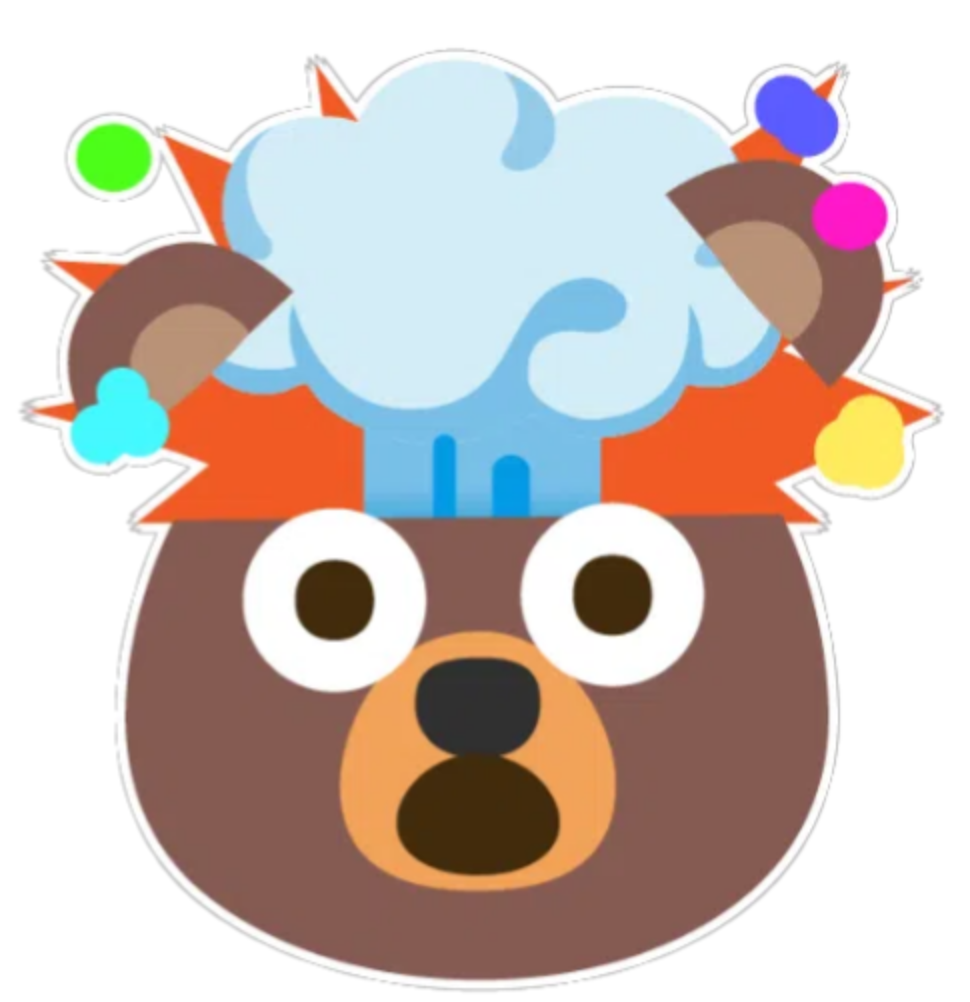

In [ ]:
class_df.to_csv("/g/korbel/centromere/cancer/pcawg_classification.tsv", sep="\t", index=False)